In [1]:
from google.colab import files
uploaded = files.upload()

Saving PremierLeagueData26-27.csv to PremierLeagueData26-27.csv


In [4]:
import pandas as pd

df = pd.read_csv(
    "PremierLeagueData26-27.csv",
    header=[0, 1]
)

df.head()

Unnamed: 0_level_0 Unnamed: 1_level_0 Unnamed: 2_level_0 Unnamed: 3_level_0  \
                  Rk             Player             Nation                Pos   
0                  1   Brenden Aaronson             us USA                 MF   
1                  2      Tammy Abraham            eng ENG                 FW   
2                  3  Joshua Acheampong            eng ENG                 DF   
3                  4        Tyler Adams             us USA                 MF   
4                  5   Tosin Adarabioyo            eng ENG                 DF   

  Unnamed: 4_level_0 Unnamed: 5_level_0 Unnamed: 6_level_0 Playing Time  \
               Squad                Age               Born           MP   
0       Leeds United             26-000               2000            6   
1        Aston Villa             29-020               1997            4   
2            Chelsea             20-170               2006            6   
3        Bournemouth             27-250               1999            7   
4          Tottenham             29-028               1997            2   

               ... Performance           Per 90 Minutes                        \
  Starts  Min  ...       PKatt CrdY CrdR            Gls  Ast  G+A G-PK G+A-PK   
0      2  217  ...           0    0    0            0.0  0.0  0.0  0.0    0.0   
1      0   74  ...           0    0    0            0.0  0.0  0.0  0.0    0.0   
2      4  403  ...           0    1    0            0.0  0.0  0.0  0.0    0.0   
3      5  459  ...           0    1    0            0.0  0.0  0.0  0.0    0.0   
4      1   76  ...           0    0    0            0.0  0.0  0.0  0.0    0.0   

  Unnamed: 24_level_0 -additional  
              Matches       -9999  
0             Matches    5bc43860  
1             Matches    f586779e  
2             Matches    b7e62e1d  
3             Matches    2b09d998  
4             Matches    c81d773d  

[5 rows x 26 columns]

In [5]:
print(df.columns.tolist()[:5])


[('Unnamed: 0_level_0', 'Rk'), ('Unnamed: 1_level_0', 'Player'), ('Unnamed: 2_level_0', 'Nation'), ('Unnamed: 3_level_0', 'Pos'), ('Unnamed: 4_level_0', 'Squad')]


In [6]:
df.columns = [
    col[1] if "Unnamed" in col[0]
    else f"{col[0]}_{col[1]}"
    for col in df.columns
]

print(df.columns.tolist())

['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Age', 'Born', 'Playing Time_MP', 'Playing Time_Starts', 'Playing Time_Min', 'Playing Time_90s', 'Performance_Gls', 'Performance_Ast', 'Performance_G+A', 'Performance_G-PK', 'Performance_PK', 'Performance_PKatt', 'Performance_CrdY', 'Performance_CrdR', 'Per 90 Minutes_Gls', 'Per 90 Minutes_Ast', 'Per 90 Minutes_G+A', 'Per 90 Minutes_G-PK', 'Per 90 Minutes_G+A-PK', 'Matches', '-additional_-9999']


In [7]:
df = df[df["Player"] != "Player"].copy()

df = df.drop(
    columns=["Matches", "-additional_-9999"],
    errors="ignore"
)

df = df.reset_index(drop=True)

In [8]:
print(df["Age"].head(10))

0    26-000
1    29-020
2    20-170
3    27-250
4    29-028
5    26-165
6    25-217
7    18-241
8    20-167
9    30-014
Name: Age, dtype: object


In [9]:
df["Age"] = (
    df["Age"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")


In [10]:
print(df[["Player", "Age"]].head(10))

              Player  Age
0   Brenden Aaronson   26
1      Tammy Abraham   29
2  Joshua Acheampong   20
3        Tyler Adams   27
4   Tosin Adarabioyo   29
5         Amine Adli   26
6  David Affengruber   25
7      Honest Ahanor   18
8        Jules Ahoka   20
9           Ola Aina   30


In [11]:
df = df.rename(columns={
    "Playing Time_MP": "MP",
    "Playing Time_Starts": "Starts",
    "Playing Time_Min": "Min",
    "Playing Time_90s": "90s",

    "Performance_Gls": "Gls",
    "Performance_Ast": "Ast",
    "Performance_G+A": "G+A",
    "Performance_G-PK": "G-PK",
    "Performance_PK": "PK",
    "Performance_PKatt": "PKatt",
    "Performance_CrdY": "CrdY",
    "Performance_CrdR": "CrdR",

    "Per 90 Minutes_Gls": "Gls_90",
    "Per 90 Minutes_Ast": "Ast_90",
    "Per 90 Minutes_G+A": "G+A_90",
    "Per 90 Minutes_G-PK": "G-PK_90",
    "Per 90 Minutes_G+A-PK": "G+A-PK_90"
})

In [12]:
numeric_columns = [
    "Born",
    "MP",
    "Starts",
    "Min",
    "90s",
    "Gls",
    "Ast",
    "G+A",
    "G-PK",
    "PK",
    "PKatt",
    "CrdY",
    "CrdR",
    "Gls_90",
    "Ast_90",
    "G+A_90",
    "G-PK_90",
    "G+A-PK_90"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [13]:
print(df["Age"].head(20).tolist())


[26, 29, 20, 27, 29, 26, 25, 18, 20, 30, 32, 28, 31, 23, 29, 22, 34, 22, 20, 23]


In [14]:
df.head()


,Rk,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,...,G-PK,PK,PKatt,CrdY,CrdR,Gls_90,Ast_90,G+A_90,G-PK_90,G+A-PK_90
0,1,Brenden Aaronson,us USA,MF,Leeds United,26,2000,6,2,217,...,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0
1,2,Tammy Abraham,eng ENG,FW,Aston Villa,29,1997,4,0,74,...,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0
2,3,Joshua Acheampong,eng ENG,DF,Chelsea,20,2006,6,4,403,...,0,0,0,1,0,0.0,0.0,0.0,0.0,0.0
3,4,Tyler Adams,us USA,MF,Bournemouth,27,1999,7,5,459,...,0,0,0,1,0,0.0,0.0,0.0,0.0,0.0
4,5,Tosin Adarabioyo,eng ENG,DF,Tottenham,29,1997,2,1,76,...,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0


In [15]:
df.describe()


,Rk,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,PK,PKatt,CrdY,CrdR,Gls_90,Ast_90,G+A_90,G-PK_90,G+A-PK_90
count,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000
mean,227.500000,25.561674,2000.255507,4.753304,3.392070,304.323789,3.379295,0.429515,0.310573,0.740088,0.411894,0.017621,0.024229,0.621145,0.028634,0.194273,0.084405,0.278744,0.189714,0.274185
std,131.202769,4.021952,4.054366,2.126450,2.726783,223.707736,2.490151,0.907711,0.682822,1.275798,0.886464,0.131715,0.167658,0.885045,0.166961,1.155551,0.276310,1.184486,1.153315,1.182294
min,1.000000,16.000000,1990.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,114.250000,23.000000,1997.000000,3.000000,1.000000,90.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,227.500000,25.000000,2000.000000,5.000000,3.000000,290.500000,3.200000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,340.750000,28.000000,2003.000000,7.000000,6.000000,523.250000,5.800000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.140000,0.000000,0.290000,0.140000,0.290000
max,454.000000,36.000000,2010.000000,7.000000,7.000000,630.000000,7.000000,8.000000,4.000000,8.000000,8.000000,1.000000,2.000000,6.000000,1.000000,22.500000,4.500000,22.500000,22.500000,22.500000


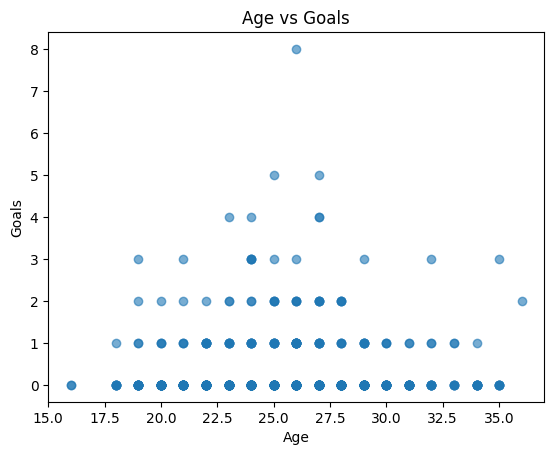

In [16]:
import matplotlib.pyplot as plt

plt.scatter(df["Age"], df["Gls"], alpha=0.6)
plt.xlabel("Age")
plt.ylabel("Goals")
plt.title("Age vs Goals")
plt.show()

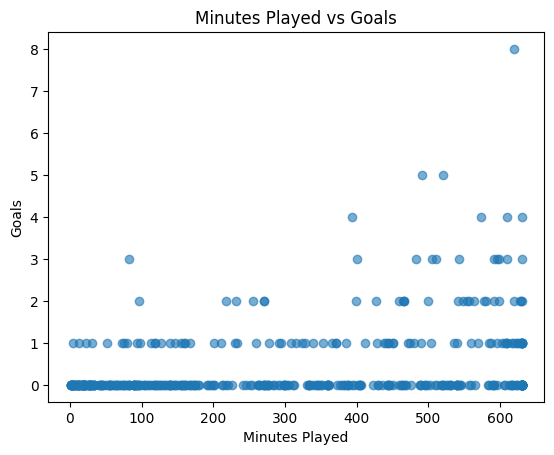

In [17]:
plt.scatter(df["Min"], df["Gls"], alpha=0.6)
plt.xlabel("Minutes Played")
plt.ylabel("Goals")
plt.title("Minutes Played vs Goals")
plt.show()

## Market Value Integration

The next step is to combine Premier League performance statistics with
player market value data. Market value will serve as the target variable
for the regression models.

In [35]:
import kagglehub

path = kagglehub.dataset_download(
    "kanchana1990/football-transfer-value-intelligence-2024"
)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'football-transfer-value-intelligence-2024' dataset.
Path to dataset files: /kaggle/input/football-transfer-value-intelligence-2024


In [36]:
import os

print(os.listdir(path))

['Football_Player_Market_Value_Trajectories']


In [37]:
folder_path = os.path.join(
    path,
    "Football_Player_Market_Value_Trajectories"
)

print(os.listdir(folder_path))

['data_dictionary.csv', 'transfermarkt_player_values.parquet', 'transfermarkt_player_values.csv', 'transfermarkt_value_history.csv']


In [39]:
market_df = pd.read_csv(
    os.path.join(
        folder_path,
        "transfermarkt_player_values.csv"
    )
)

market_df.head()

,player_id,name,age,nationality,position,position_group,current_club,league_name,current_value_eur,current_value_tier,...,mean_yoy_growth_rate,num_valuation_points,num_clubs_career,trajectory,is_at_peak,ever_100m,ever_50m,ever_10m,data_source,dataset_built_at
0,418560,Erling Haaland,25.0,Norway,€200.00m,Other,Norway,Premier League,200000000.0,World Class (100M+),...,1.6329,26,5,growing,0,1,1,1,Transfermarkt.com,2026-02-21
1,433177,Bukayo Saka,24.0,England,€130.00m,Other,England,Premier League,130000000.0,World Class (100M+),...,0.6972,22,1,growing,0,1,1,1,Transfermarkt.com,2026-02-21
2,357662,Declan Rice,27.0,England,€120.00m,Other,England,Premier League,120000000.0,World Class (100M+),...,1.6100,24,2,growing,0,1,1,1,Transfermarkt.com,2026-02-21
3,568177,Cole Palmer,23.0,England,€120.00m,Other,England,Premier League,120000000.0,World Class (100M+),...,2.0823,15,3,growing,0,1,1,1,Transfermarkt.com,2026-02-21
4,349066,Alexander Isak,26.0,Sweden,€120.00m,Other,Sweden,Premier League,120000000.0,World Class (100M+),...,1.5154,28,6,growing,0,1,1,1,Transfermarkt.com,2026-02-21


In [40]:
epl_market_df = market_df[
    market_df["league_name"] == "Premier League"
].copy()

print(epl_market_df.shape)

epl_market_df[
    ["name", "age", "position", "current_club", "current_value_eur"]
].head(10)

(103, 36)


,name,age,position,current_club,current_value_eur
0,Erling Haaland,25.0,€200.00m,Norway,200000000.0
1,Bukayo Saka,24.0,€130.00m,England,130000000.0
2,Declan Rice,27.0,€120.00m,England,120000000.0
3,Cole Palmer,23.0,€120.00m,England,120000000.0
4,Alexander Isak,26.0,€120.00m,Sweden,120000000.0
5,Moisés Caicedo,24.0,€110.00m,Ecuador,110000000.0
6,Florian Wirtz,22.0,€110.00m,Germany,110000000.0
7,William Saliba,24.0,€90.00m,France,90000000.0
8,Ryan Gravenberch,23.0,€90.00m,Netherlands,90000000.0
9,Enzo Fernández,25.0,€85.00m,Argentina,85000000.0


In [43]:
model_df = df.merge(
    epl_market_df,
    left_on="Player",
    right_on="name",
    how="inner"
)

print("FBref players:", len(df))
print("Market value players:", len(epl_market_df))
print("Matched players:", len(model_df))

FBref players: 454
Market value players: 103
Matched players: 79


In [48]:
model_df[
    ["Player", "Squad", "Age", "Gls", "Ast", "current_value_eur"]
].head(15)



,Player,Squad,Age,Gls,Ast,current_value_eur
0,Elliot Anderson,Manchester City,23,0,1,60000000.0
1,Carlos Baleba,Manchester Utd,22,0,0,60000000.0
2,Lucas Bergvall,Tottenham,20,0,0,40000000.0
3,Jarrad Branthwaite,Everton,24,0,0,45000000.0
4,Moisés Caicedo,Chelsea,24,0,0,110000000.0
5,Riccardo Calafiori,Arsenal,24,1,2,50000000.0
6,Rayan Cherki,Manchester City,23,4,2,50000000.0
7,Levi Colwill,Chelsea,23,0,0,50000000.0
8,Matheus Cunha,Manchester Utd,27,1,2,70000000.0
9,Liam Delap,Nottingham,23,1,0,35000000.0


In [49]:
features = [
    "Age",
    "Pos",
    "MP",
    "Starts",
    "Min",
    "Gls",
    "Ast",
    "Gls_90",
    "Ast_90"
]

target = "current_value_eur"

model_df[features + [target]].isna().sum()

,0
Age,0
Pos,0
MP,0
Starts,0
Min,0
Gls,0
Ast,0
Gls_90,0
Ast_90,0
current_value_eur,0


In [50]:
model_data = model_df[
    features + [target]
].dropna()

print("Players used for modeling:", len(model_data))

Players used for modeling: 79


In [51]:
X = model_data[features]
y = model_data[target]

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "Age",
    "MP",
    "Starts",
    "Min",
    "Gls",
    "Ast",
    "Gls_90",
    "Ast_90"
]

categorical_features = ["Pos"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set:", len(X_train))
print("Test set:", len(X_test))

Training set: 63
Test set: 16


In [54]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['Age', 'MP', 'Starts', 'Min',
                                                   'Gls', 'Ast', 'Gls_90',
                                                   'Ast_90']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Pos'])])),
                ('model', LinearRegression())])

In [55]:
linear_predictions = linear_model.predict(X_test)

In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression")
print(f"MAE: €{linear_mae:.2f}M")
print(f"RMSE: €{linear_rmse:.2f}M")
print(f"R²: {linear_r2:.3f}")

Linear Regression
MAE: €32398428.42M
RMSE: €51798684.64M
R²: -0.559


Linear Regression was used as the initial baseline model. The model produced an R² of -0.559, indicating that a simple linear relationship between the selected performance variables and player market value was insufficient to explain market valuation.

That gives you justification for trying more sophisticated models.
Why Linear Regression may struggle here
Football market value probably isn't linear.

For example, suppose two forwards have:
- Player A
* Age: 31
- Goals: 20
- Value: €30M

- Player B
- Age: 22
- Goals: 20
- Value: €100M

Their performance looks similar, but the younger player can be worth dramatically more because of future potential.

In [57]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [58]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest")
print(f"MAE: €{rf_mae / 1_000_000:.2f} million")
print(f"RMSE: €{rf_rmse / 1_000_000:.2f} million")
print(f"R²: {rf_r2:.3f}")

Random Forest
MAE: €25.15 million
RMSE: €41.52 million
R²: -0.001


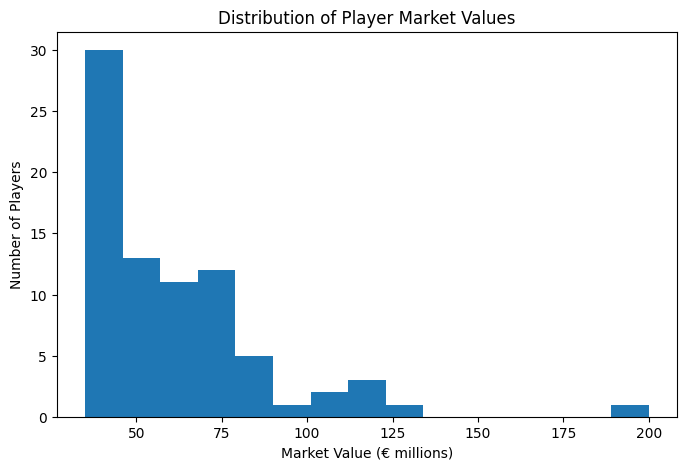

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(model_df["current_value_eur"] / 1_000_000, bins=15)

plt.xlabel("Market Value (€ millions)")
plt.ylabel("Number of Players")
plt.title("Distribution of Player Market Values")

plt.show()

In [60]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        random_state=42,
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2
    ))
])

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)

In [61]:
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting")
print(f"MAE: €{gb_mae / 1_000_000:.2f} million")
print(f"RMSE: €{gb_rmse / 1_000_000:.2f} million")
print(f"R²: {gb_r2:.3f}")

Gradient Boosting
MAE: €27.85 million
RMSE: €46.14 million
R²: -0.237


In [62]:
y_log = np.log1p(model_data["current_value_eur"])

In [63]:
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X,
    y_log,
    test_size=0.2,
    random_state=42
)

In [64]:
rf_log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42
    ))
])

rf_log_model.fit(X_train_log, y_train_log)

log_predictions = rf_log_model.predict(X_test_log)

In [65]:
rf_log_predictions_eur = np.expm1(log_predictions)
y_test_eur = np.expm1(y_test_log)

In [66]:
rf_log_mae = mean_absolute_error(
    y_test_eur,
    rf_log_predictions_eur
)

rf_log_rmse = np.sqrt(
    mean_squared_error(
        y_test_eur,
        rf_log_predictions_eur
    )
)

rf_log_r2 = r2_score(
    y_test_eur,
    rf_log_predictions_eur
)

print("Random Forest — Log Target")
print(f"MAE: €{rf_log_mae / 1_000_000:.2f} million")
print(f"RMSE: €{rf_log_rmse / 1_000_000:.2f} million")
print(f"R²: {rf_log_r2:.3f}")

Random Forest — Log Target
MAE: €25.24 million
RMSE: €43.18 million
R²: -0.083


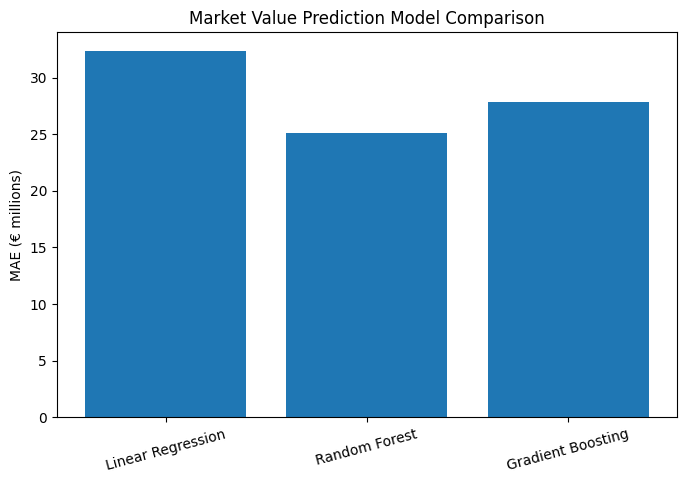

In [67]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae / 1_000_000,
        rf_mae / 1_000_000,
        gb_mae / 1_000_000
    ]
})

plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["MAE"])
plt.ylabel("MAE (€ millions)")
plt.title("Market Value Prediction Model Comparison")
plt.xticks(rotation=15)
plt.show()

In [68]:
features = [
    "Age",
    "Pos",
    "Min",
    "Gls",
    "Ast",
    "Gls_90",
    "Ast_90"
]

target = "current_value_eur"

In [69]:
model_data = model_df[features + [target]].copy()

model_data["Pos"] = (
    model_data["Pos"]
    .str.split(",")
    .str[0]
)

model_data = model_data.dropna()

In [70]:
import numpy as np

X = model_data[features]
y = np.log1p(model_data[target])

In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "Age",
    "Min",
    "Gls",
    "Ast",
    "Gls_90",
    "Ast_90"
]

categorical_features = ["Pos"]

preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

In [72]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=500,
        max_depth=5,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42
    ))
])

In [73]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

final_model.fit(X_train, y_train)

pred_log = final_model.predict(X_test)

pred_eur = np.expm1(pred_log)
actual_eur = np.expm1(y_test)

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(actual_eur, pred_eur)
rmse = np.sqrt(mean_squared_error(actual_eur, pred_eur))
r2 = r2_score(actual_eur, pred_eur)

print("Final Random Forest Model")
print(f"MAE: €{mae / 1_000_000:.2f} million")
print(f"RMSE: €{rmse / 1_000_000:.2f} million")
print(f"R²: {r2:.3f}")

Final Random Forest Model
MAE: €23.96 million
RMSE: €42.01 million
R²: -0.025


In [75]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    final_model,
    X,
    y,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

print("Cross-validation log-MAE:")
print(-cv_scores)
print("Average:", -cv_scores.mean())

Cross-validation log-MAE:
[0.31268349 0.30284339 0.26874345 0.24578713 0.24500527]
Average: 0.27501254739412684


In [76]:
from sklearn.compose import TransformedTargetRegressor

final_model_eur = TransformedTargetRegressor(
    regressor=final_model,
    func=np.log1p,
    inverse_func=np.expm1
)

In [77]:
X = model_data[features]
y_eur = model_data["current_value_eur"]

In [78]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_mae = -cross_val_score(
    final_model_eur,
    X,
    y_eur,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

print("MAE by fold:")
print(cv_mae / 1_000_000)

print(
    f"Average CV MAE: €{cv_mae.mean() / 1_000_000:.2f} million"
)

print(
    f"Std. deviation: €{cv_mae.std() / 1_000_000:.2f} million"
)

MAE by fold:
[23.96899856 18.37905141 16.39758914 14.63481194 14.26326011]
Average CV MAE: €17.53 million
Std. deviation: €3.54 million


In [79]:
cv_mse = -cross_val_score(
    final_model_eur,
    X,
    y_eur,
    cv=cv,
    scoring="neg_mean_squared_error"
)

cv_rmse = np.sqrt(cv_mse)

print(
    f"Average CV RMSE: €{cv_rmse.mean() / 1_000_000:.2f} million"
)

Average CV RMSE: €24.68 million


In [80]:
cv_r2 = cross_val_score(
    final_model_eur,
    X,
    y_eur,
    cv=cv,
    scoring="r2"
)

print("R² by fold:")
print(cv_r2)

print(f"Average CV R²: {cv_r2.mean():.3f}")

R² by fold:
[-0.02965     0.14736369 -0.02805385  0.09267458  0.24190236]
Average CV R²: 0.085


In [81]:
final_model_eur.fit(X, y_eur)

TransformedTargetRegressor(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>,
                           regressor=Pipeline(steps=[('preprocessor',
                                                      ColumnTransformer(transformers=[('num',
                                                                                       'passthrough',
                                                                                       ['Age',
                                                                                        'Min',
                                                                                        'Gls',
                                                                                        'Ast',
                                                                                        'Gls_90',
                                                                                        'Ast_90']),
                                                                                      ('cat',
                                                                                       OneHotEncoder(handle_unknown='ignore'),
                                                                                       ['Pos'])])),
                                                     ('model',
                                                      RandomForestRegressor(max_depth=5,
                                                                            max_features='sqrt',
                                                                            min_samples_leaf=2,
                                                                            min_samples_split=4,
                                                                            n_estimators=500,
                                                                            random_state=42))]))

In [82]:
import joblib

joblib.dump(
    final_model_eur,
    "premier_league_market_value_model.pkl"
)

['premier_league_market_value_model.pkl']

In [83]:
from google.colab import files

files.download("premier_league_market_value_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>